## CIND820 Data Analysis

In [6]:
import pandas as pd

new = pd.read_csv('2026-27 QMJHL PBP prepared.csv')

In [7]:
new.describe()

,period_id,s,x_location,y_location,home,game_id,score_diff,s_since_prev,x_prev,y_prev,distance_prev,shot_distance,shot_angle
count,9431.000000,9431.000000,9431.000000,9431.000000,9431.000000,9431.000000,9431.000000,8912.00000,8912.000000,8912.000000,8912.000000,9431.000000,9431.000000
mean,2.022267,1829.237196,41.190613,43.092684,0.517018,32925.551373,-0.031916,58.02996,98.171716,42.442106,66.654598,34.989275,28.037638
std,0.835539,1040.649928,22.339350,18.095789,0.499737,170.765831,1.950158,58.03096,62.865971,18.104641,49.606158,22.672583,18.661977
min,1.000000,8.000000,2.333333,0.850000,0.000000,32651.000000,-11.000000,1.00000,3.000000,0.000000,0.437480,3.253033,0.000000
25%,1.000000,938.500000,24.333333,30.883333,0.000000,32782.000000,-1.000000,17.00000,35.000000,30.316667,24.240899,17.231516,13.365964
50%,2.000000,1832.000000,36.000000,42.500000,1.000000,32915.000000,0.000000,40.00000,72.000000,42.500000,48.124175,30.802038,26.243297
75%,3.000000,2720.000000,55.000000,55.250000,1.000000,33073.000000,1.000000,80.00000,163.666667,54.400000,114.866699,49.410975,38.756723
max,4.000000,3899.000000,197.000000,85.000000,1.000000,33208.000000,11.000000,604.00000,197.666667,84.150000,183.172244,187.626284,116.631315


The DataFrame description table above shows the counts, means, standard deviations, and ranges for all of the numerical variables in the dataset. The 'count' row shows that for most variables, the columns are fully populated. The exceptions are 's_since_prev,' 'x_prev,' 'y_prev,' and 'distance_prev' because they take a 'NaN' value when they are the first shot of the period. Therefore, there are 519 periods of data in this dataset (of games up to November 9th, 2026).

#### period_id

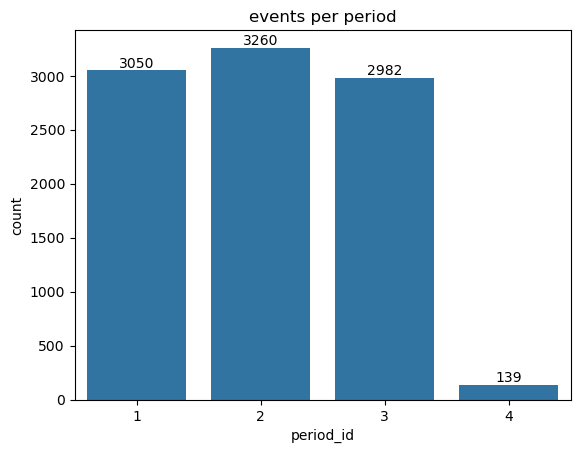

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

per_count = sns.countplot(data=new, x='period_id')
per_chart = per_count.bar_label(per_count.containers[0])

plt.title('events per period')
plt.show(per_chart)

The bar chart above shows the distribution of events by period. The second period has the most number of shot events, followed by the first period and then very closely by the third period. There are remarkably fewer events where 'period_id' = 4 because overtime is only played if the score is still tied at the end of the third period, plus the overtime period itself is only five minutes long (as opposed to the other three periods being 20 minutes long).

#### s

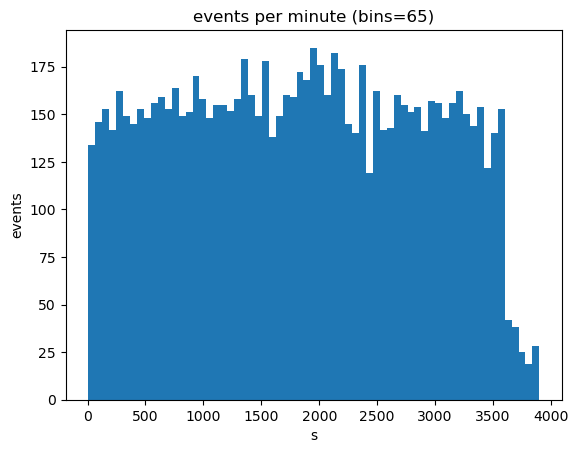

In [27]:
s_chart = plt.hist(data=new, x='s', bins=65)

plt.title('events per minute (bins=65)')
plt.ylabel('events')
plt.xlabel('s')
plt.show(s_chart)

The histogram above shows the number of events at each approximate minute-long (60-second) interval.

#### x_location and y_location

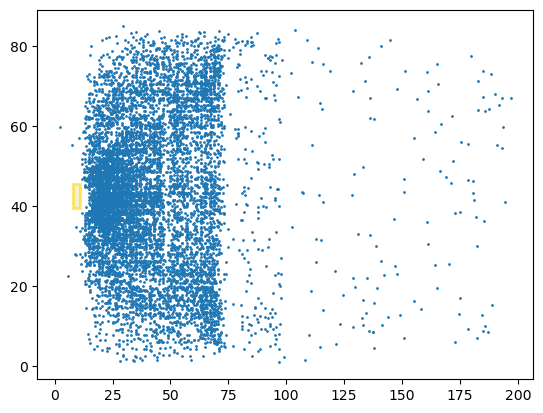

In [29]:
import matplotlib.patches as patches

fig, ax = plt.subplots()

shot_scatter = ax.scatter(data=new, x='x_location', y='y_location', s=1)

net = patches.Rectangle((8, 39.5), 3, 6, facecolor='palegoldenrod', edgecolor='gold', linewidth=2, alpha=0.6)
ax.add_patch(net)

plt.show()

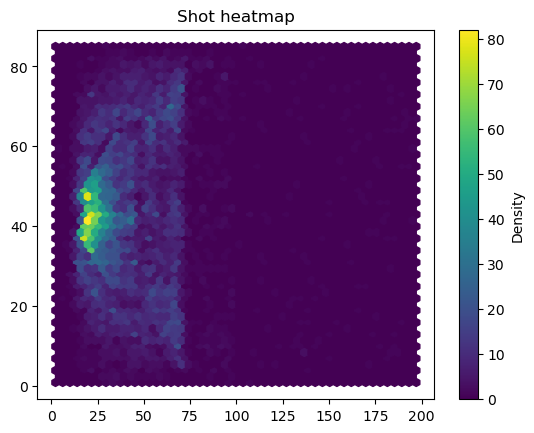

In [33]:
plt.hexbin(data=new, x='x_location', y='y_location', gridsize=50)

plt.colorbar(label='Density')
plt.title('Shot heatmap')
plt.show()

The two scatterplots above show the same data - the x_location and y_location of every event in the dataset (n=9431). With almost 10,000 observations, I chose to display this data with a heatmap as well to show the density of observations, especially around where the net would be (the yellow box in the first scatterplot).

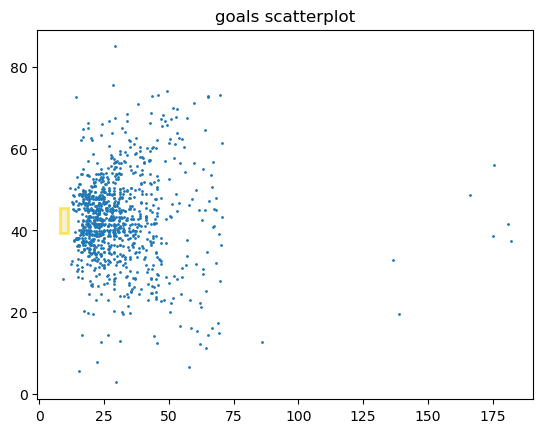

In [36]:
goals_df = new[new['event'] == 'goal']

fig, ax = plt.subplots()

shot_scatter = ax.scatter(data=goals_df, x='x_location', y='y_location', s=1)

net = patches.Rectangle((8, 39.5), 3, 6, facecolor='palegoldenrod', edgecolor='gold', linewidth=2, alpha=0.6)
ax.add_patch(net)

plt.title('goals scatterplot')
plt.show()

#### Correcting outlier goals

Graphing just the goals, we can see that there are a few clear outliers outside of our defined offensive-zone range of 'x_location' = (0, 100). Because we removed empty net goals from our database, we can assume that these values were inputted/transformed incorrectly, as it is extremely unlikely that a goal would be scored on a goaltender from that far away. Upon reviewing the game footage (on the QMJHL Game Centres) for the seven goals in the table below, it was concluded that these goals did not happen this far away from the net. Therefore, we will transform these goals into values that fit our range of 'x_location' = (0, 100).

Shots from this far away will not be transformed, because it is possible and infrequently common for shots to be taken from this far away. We can see in the original event scatterplot above that these events are much less common than shots taken in the offensive zone. We will not consider these outliers to be discarded or adjusted because the volume is too high to verify each one on video, but we must adjust the goals inputted incorrectly to ensure the quality of the prediction models.

In [9]:
new[(new['event'] == 'goal') & (new['x_location'] > 100)]

,event,period_id,s,x_location,y_location,home,player_team_id,goalie_team_id,player,goalie,game_id,score_diff,strength,s_since_prev,x_prev,y_prev,distance_prev,shot_distance,shot_angle
1223,goal,1,57,139.000000,19.550000,0.0,Moncton,Saint John,Shayne Gould,Samuel Meloche,33070,-3,5v5,NaN,NaN,NaN,NaN,130.041157,10.164947
2157,goal,2,1578,175.000000,38.533333,0.0,Charlottetown,Victoriaville,Kimani Eccleston,Andrei Nikolayev,33203,-1,5v5,17.0,174.000000,56.100000,149.311088,164.047964,1.385542
2850,goal,1,397,175.333333,56.100000,0.0,Rouyn-Noranda,Newfoundland,Charles Laforest,Louis-Antoine Denault,32944,0,5v4,243.0,135.333333,60.066667,114.971615,164.895132,4.730939
3318,goal,1,939,136.333333,32.866667,1.0,Victoriaville,Shawinigan,Xavier Lebel,Philippe Boucher,33204,0,5v5,55.0,71.333333,44.200000,65.980637,125.703005,4.395210
5792,goal,2,2199,182.000000,37.400000,0.0,Quebec,Victoriaville,Egan Beveridge,Anthony Catanzariti,33205,5,5v5,13.0,183.333333,47.883333,10.567784,171.076036,1.708315
5823,goal,1,855,181.000000,41.650000,1.0,Victoriaville,Sherbrooke,Thomas Desruisseaux,Kyan Labbé,33206,0,5v4,213.0,34.333333,79.900000,39.636014,170.002125,0.286477
8521,goal,1,756,166.333333,48.733333,0.0,Blainville-Boisbriand,Chicoutimi,Matt Gosselin,Patriks Plumins,32787,0,5v5,1.0,27.333333,46.750000,12.247914,155.458351,2.297975


In the transformations below, 'x_location' must be transformed last because np.where() takes the "'x_location' >" condition to determine whether or not the other variables should be adjusted.

In [10]:
import numpy as np

new['x_prev'] = np.where((new['event'] == 'goal').shift(-1) & (new['x_location'] > 100).shift(-1), 200 - new['x_prev'], new['x_prev'])
new['y_prev'] = np.where((new['event'] == 'goal').shift(-1) & (new['x_location'] > 100).shift(-1), 85 - new['y_prev'], new['y_prev'])
new['y_location'] = np.where((new['event'] == 'goal') & (new['x_location'] > 100), 85 - new['y_location'], new['y_location'])
new['x_location'] = np.where((new['event'] == 'goal') & (new['x_location'] > 100), 200 - new['x_location'], new['x_location'])

With these changes, we also need to recalculate distance_prev, shot_distance, and shot_angle.

In [11]:
net_location = (11, 42.5)

new['distance_prev'] = np.sqrt((new['x_location'] - new['x_prev']) ** 2 + (new['y_location'] - new['y_prev']) ** 2)
new['shot_distance'] = np.sqrt((new['x_location'] - net_location[0]) ** 2 + (new['y_location'] - net_location[1]) ** 2)
new['shot_angle'] = (np.degrees(np.arctan2((new['y_location'] - net_location[1]), (new['x_location'] - net_location[0])))).abs()

In [12]:
new.to_csv('2026-27 QMJHL PBP prepared.csv', index=False)

#### home

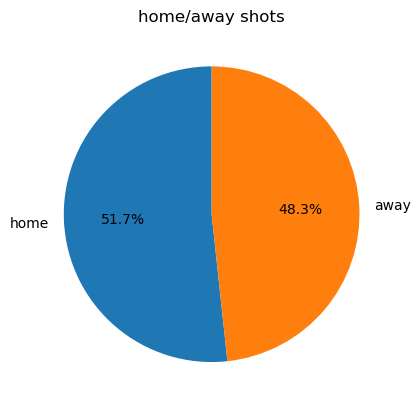

In [41]:
home_counts = new['home'].value_counts()
home_pie = home_counts.plot.pie(
    autopct="%1.1f%%",
    startangle=90,
    labels=['home', 'away'],
    ylabel="",
)

plt.title('home/away shots')
plt.show(home_pie)

As also shown in the 'mean' under 'home' in the DataFrame description table, the home team takes about 7% more shots than the away team in a game. "Home-ice advantage" and the 'home' binary classifier could potentially be a factor in the regression models.

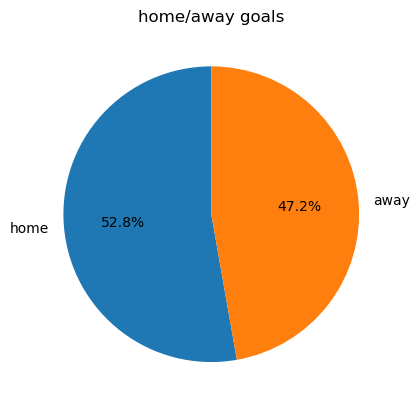

In [42]:
home_goal_counts = new['home'].where(new['event'] == 'goal').value_counts()
home_goal_pie = home_goal_counts.plot.pie(
    autopct="%1.1f%%",
    startangle=90,
    labels=['home', 'away'],
    ylabel="",
)

plt.title('home/away goals')
plt.show(home_goal_pie)

The home team has an even greater advantage in goal-scoring - the home team scores 52.8% of all goals in games. This is another indicator that the 'home' variable may play a significant role in the models.

#### score_diff

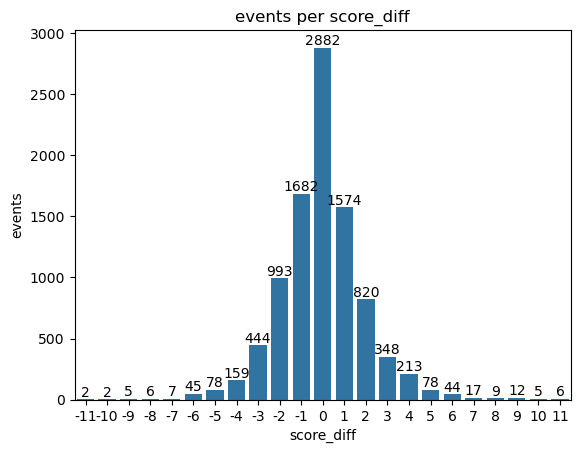

In [43]:
score_count = sns.countplot(data=new, x='score_diff')
score_chart = score_count.bar_label(score_count.containers[0])

plt.title('events per score_diff')
plt.ylabel('events')
plt.show(score_chart)

Graphing the frequency of events by score differential yields some interesting results. Of course, score_diff = 0 has the most events, as every game starts with this score differential by default. It is the one score_diff value that is guaranteed to be found in every game.

Looking at the positive-negative pairs (1 and -1, 2 and -2, etc.) can give us some information about 'score effects,' which has been explored at the NHL level and is part of why it is a variable in this QMJHL expected goals model. In the data, teams that were down by one, two, or three outshot the other team in each case. However, teams that were up by four outshot their losing opponent. Teams down by five were able to equal their opponents' shots on average, but this is where the sample starts to get very small. At the very high score differentials, the winning team began outshooting the losing team.

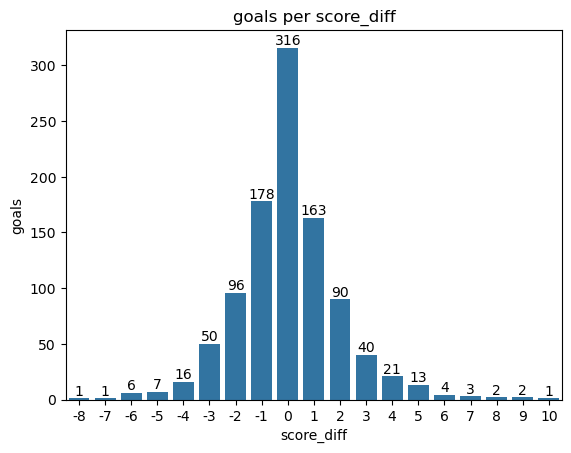

In [44]:
score_goal_count = sns.countplot(data=goals_df, x='score_diff')
score_goal_chart = score_goal_count.bar_label(score_goal_count.containers[0])

plt.title('goals per score_diff')
plt.ylabel('goals')
plt.show(score_goal_chart)

When we look at goals only, go-ahead goals are the most common (scored when the game is tied) for the same reasons as above - every game starts out tied. Atop the 161 goals that would be the first goals in the game included here, there are an additional 155 goals in the dataset that broke a tie score that was not 0-0 (1-1, 2-2, etc.). The second most common situation in the dataset is a game-tying goal, scored by a team down by one (score_diff = -1). Again, for teams down by one, two, or three, it was more common that they would score the next goal rather than the winning team.

#### s_since_prev

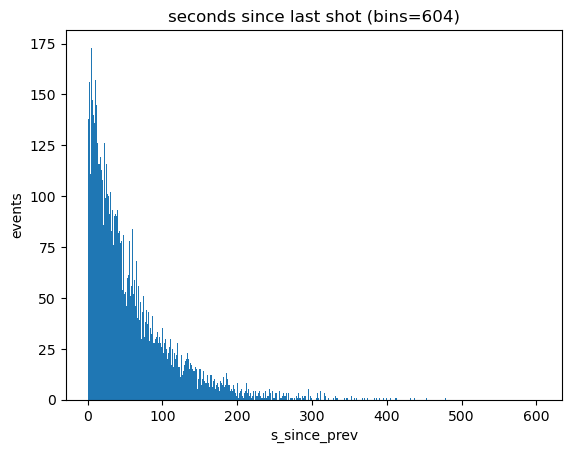

In [45]:
s_since_chart = plt.hist(data=new, x='s_since_prev', bins=604)

plt.title('seconds since last shot (bins=604)')
plt.ylabel('events')
plt.xlabel('s_since_prev')
plt.show(s_since_chart)

Graphing a histogram of the s_since_prev values by frequency, with 604 bins to represent the maximum s_since_prev value of 604. The single most common s_since_prev value appears to be = 4, with high frequencies all across the range from 1 to 10. It tapers off, drops off, then has another small peak at around s_since_prev = 50.

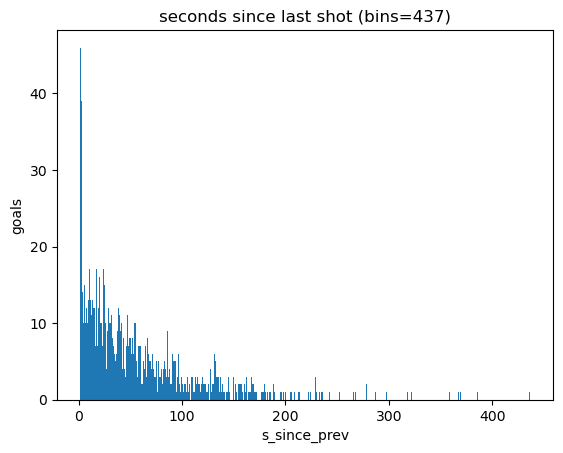

In [46]:
s_since_goal_chart = plt.hist(data=goals_df, x='s_since_prev', bins=437)

plt.title('seconds since last shot (bins=437)')
plt.ylabel('goals')
plt.xlabel('s_since_prev')
plt.show(s_since_goal_chart)

When we graph out just goals, the value of shots taken just 1 or 2 seconds after the previous shot increases greatly.

#### distance_prev

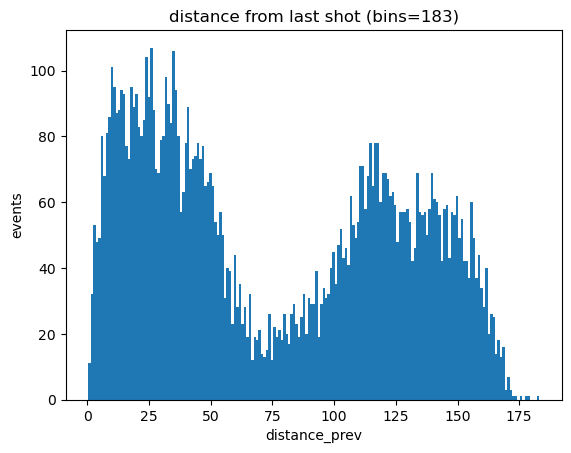

In [52]:
prev_dist_chart = plt.hist(data=new, x='distance_prev', bins=183)

plt.title('distance from last shot (bins=183)')
plt.ylabel('events')
plt.xlabel('distance_prev')
plt.show(prev_dist_chart)

This data shows two peaks with a valley in between. Possibly, the first peak from around 0 to 50 ft came from shots taken sequentially by the same team, and the second smaller peak from about 100 to 150 ft came from shots taken by a team after the previous shot was taken by their opponents in the other end of the ice. The dip at around 50 to 100 ft perhaps represents the distance from typical shooting locations to the neutral zone (the middle of the ice, far away from both nets), where very few shots are taken.

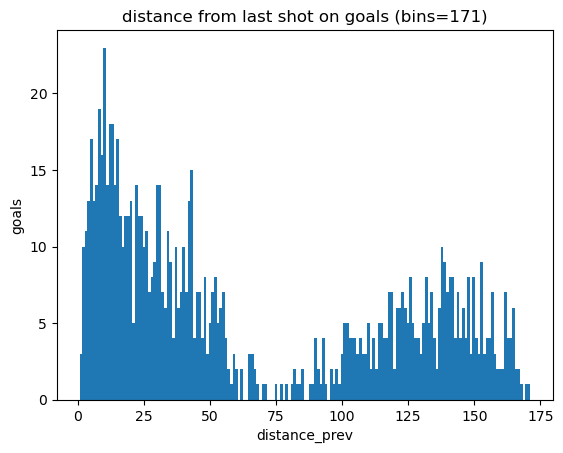

In [54]:
prev_dist_g_chart = plt.hist(data=goals_df, x='distance_prev', bins=171)

plt.title('distance from last shot on goals (bins=171)')
plt.ylabel('goals')
plt.xlabel('distance_prev')
plt.show(prev_dist_g_chart)

This pattern holds with the smaller sample of goals in the dataset, though the peak when the distance between shots is smaller is much higher relatively.

#### shot_distance

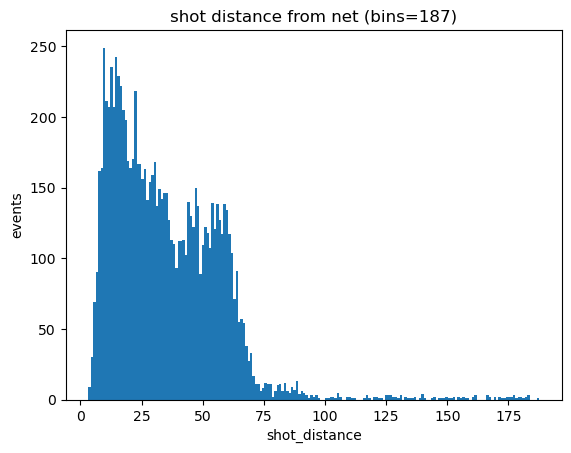

In [56]:
distance_chart = plt.hist(data=new, x='shot_distance', bins=187)

plt.title('shot distance from net (bins=187)')
plt.ylabel('events')
plt.xlabel('shot_distance')
plt.show(distance_chart)

The distance of shots from the middle of the net seems to fall most commonly between 5 and 20 ft, although up to around 65 ft is frequent. There are very few shots taken at a distance of over 75 ft away from the net.

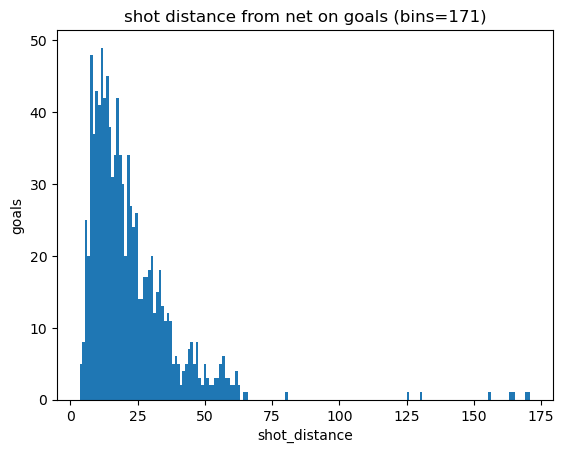

In [58]:
goals_distance_chart = plt.hist(data=goals_df, x='shot_distance', bins=171)

plt.title('shot distance from net on goals (bins=171)')
plt.ylabel('goals')
plt.xlabel('shot_distance')
plt.show(goals_distance_chart)

On goals, the results are a bit more evenly distributed between very close to the net (shot_distance < 25 ft) and mid-range distances (such as between 25 and 40 ft).

#### shot_angle

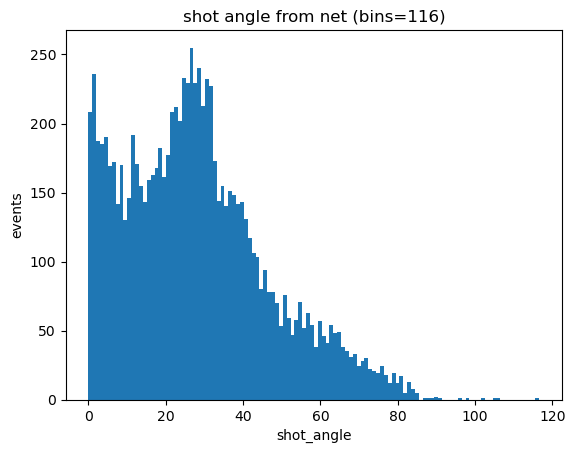

In [61]:
angle_chart = plt.hist(data=new, x='shot_angle', bins=116)

plt.title('shot angle from net (bins=116)')
plt.ylabel('events')
plt.xlabel('shot_angle')
plt.show(angle_chart)

For the angle of shots, it's very common to shoot directly in front of the net (where y_location = 42.5 ft) or at a slight angle between 20 and 30 degrees.

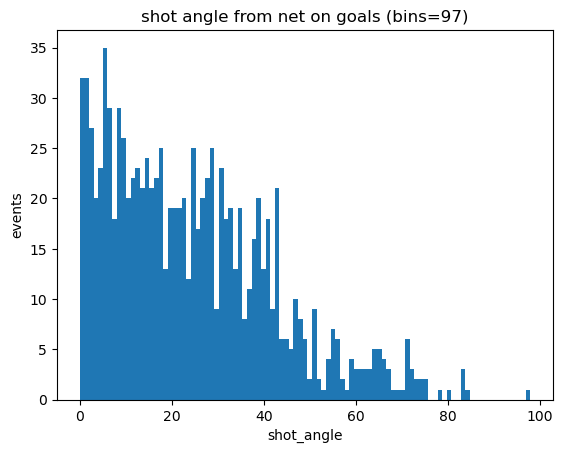

In [ ]:
angle_goal_chart = plt.hist(data=goals_df, x='shot_angle', bins=97)

plt.title('shot angle from net on goals (bins=97)')
plt.ylabel('goals')
plt.xlabel('shot_angle')
plt.show(angle_goal_chart)

On goals, there are fewer and fewer goals in the dataset the more extreme the angle. This histogram suggests that the shot angle may be a significant variable in the regression models, with a higher incidence of goals the lower the shot angle is.